# ⚽ FIFA 19 Comprehensive Player Analysis & Scouting Dashboard
> Students: Vora Maurya Prakashkumar (IU2441230547),  Saradava Rushil Shantilal (IU2441230513)

> Course: Python Programming

> Guide: Prof. Vatsal Shinghala

> GitHub: https://github.com/mouryaVora03/fifa-19-player-data

## 1. Environment & Library Configuration

In [5]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from IPython.display import display

# Suppress minor non-critical warnings
warnings.filterwarnings("ignore")

# Configure premium visualization theme
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "semibold",
    "axes.edgecolor": "#D1D5DB",
    "axes.linewidth": 1.2,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "grid.color": "#9CA3AF"
})

print("✓ Environment configured successfully.")

✓ Environment configured successfully.


## 2. Data Ingestion & Schema Exploration

In [6]:
# Detect execution environment and locate data source
csv_file = "kl.csv"

try:
    from google.colab import files
    if not os.path.exists(csv_file):
        print("Google Colab detected. Please upload 'kl.csv':")
        uploaded = files.upload()
        csv_file = next(iter(uploaded.keys()))
except ImportError:
    pass

# Load raw dataset
df = pd.read_csv(csv_file, encoding="cp1252", low_memory=False)

# Clean column headers and remove unnamed index artifacts
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.str.contains(r"^Unnamed", case=False)]

print(f"✓ Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head(5))

✓ Dataset loaded successfully: 18,207 rows × 88 columns


,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31.0,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94.0,94,FC Barcelona,https://cdn.sofifa.org/teams/2/light/241.png,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33.0,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94.0,94,Juventus,https://cdn.sofifa.org/teams/2/light/45.png,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26.0,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92.0,93,Paris Saint-Germain,https://cdn.sofifa.org/teams/2/light/73.png,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27.0,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91.0,93,Manchester United,https://cdn.sofifa.org/teams/2/light/11.png,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27.0,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91.0,92,Manchester City,https://cdn.sofifa.org/teams/2/light/10.png,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


## 3. Data Preprocessing & Feature Engineering

In [7]:
# 1. Deduplication
initial_count = len(df)
df = df.drop_duplicates()
removed_dups = initial_count - len(df)

# 2. String normalization
string_cols = ["Name", "Nationality", "Club", "Position"]
for col in string_cols:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# 3. Currency conversion helper
def clean_currency(val):
    """Convert currency strings (e.g. '€110.5M', '€565K') into numeric values in Euros."""
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    s = re.sub(r"[€‐–—‒, ]", "", s)
    if not s or s.lower() in {"nan", "none"}:
        return np.nan
    mult = 1.0
    if s.endswith("M"):
        mult = 1_000_000.0
        s = s[:-1]
    elif s.endswith("K"):
        mult = 1_000.0
        s = s[:-1]
    try:
        return float(s) * mult
    except ValueError:
        return np.nan

for col in ["Value", "Wage", "Release Clause"]:
    if col in df.columns:
        df[col] = df[col].apply(clean_currency)

# 4. Height & Weight parsing
def convert_height(val):
    """Convert height string from feet'inches (e.g. 5'11) to total inches."""
    if pd.isna(val):
        return np.nan
    match = re.match(r"^\s*(\d+)'(\d+)\s*$", str(val))
    if match:
        return int(match.group(1)) * 12 + int(match.group(2))
    return np.nan

def convert_weight(val):
    """Extract numeric weight in pounds (lbs) from strings (e.g. '175lbs')."""
    if pd.isna(val):
        return np.nan
    match = re.search(r"(\d+(?:\.\d+)?)", str(val))
    return float(match.group(1)) if match else np.nan

if "Height" in df.columns:
    df["Height"] = df["Height"].apply(convert_height)
if "Weight" in df.columns:
    df["Weight"] = df["Weight"].apply(convert_weight)

# 5. Contract and Date parsing
if "Joined" in df.columns:
    df["Joined"] = pd.to_datetime(df["Joined"], errors="coerce")
if "Contract Valid Until" in df.columns:
    df["Contract Valid Until"] = pd.to_numeric(df["Contract Valid Until"], errors="coerce")

# 6. Missingness Imputation
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
for col in numeric_cols:
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "string"]).columns:
    if df[col].isna().any():
        mode_val = df[col].mode(dropna=True)
        df[col] = df[col].fillna(mode_val.iloc[0] if not mode_val.empty else "Unknown")

# 7. Feature Engineering: Age Groups & Tactical Position Groups
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 25, 30, 35, 100],
    labels=["Under 21", "21-25", "26-30", "31-35", "36+"],
    include_lowest=True
)

position_groups = {
    "GK": "Goalkeeper",
    "CB": "Defender", "LB": "Defender", "RB": "Defender", "LCB": "Defender", "RCB": "Defender", "LWB": "Defender", "RWB": "Defender",
    "CDM": "Midfielder", "CM": "Midfielder", "LCM": "Midfielder", "RCM": "Midfielder", "LDM": "Midfielder", "RDM": "Midfielder",
    "CAM": "Midfielder", "LAM": "Midfielder", "RAM": "Midfielder", "LM": "Midfielder", "RM": "Midfielder",
    "ST": "Forward", "CF": "Forward", "LF": "Forward", "RF": "Forward", "LS": "Forward", "RS": "Forward", "LW": "Forward", "RW": "Forward"
}
df["Position Group"] = df["Position"].map(position_groups).fillna("Other")

# Summary of cleaning
print("─" * 50)
print("✓ Data Cleaning & Transformation Audit:")
print(f"  • Rows Remaining: {len(df):,}")
print(f"  • Total Attributes: {df.shape[1]}")
print(f"  • Duplicates Removed: {removed_dups}")
print(f"  • Missing Values in Datetime/Contract: {int(df.isna().sum().sum())}")
print("─" * 50)
display(df[["Name", "Age", "Age Group", "Position", "Position Group", "Overall", "Potential", "Value", "Wage"]].head())

──────────────────────────────────────────────────
✓ Data Cleaning & Transformation Audit:
  • Rows Remaining: 18,207
  • Total Attributes: 90
  • Duplicates Removed: 0
  • Missing Values in Datetime/Contract: 1553
──────────────────────────────────────────────────


,Name,Age,Age Group,Position,Position Group,Overall,Potential,Value,Wage
0,L. Messi,31.0,31-35,RF,Forward,94.0,94,110500000.0,565000.0
1,Cristiano Ronaldo,33.0,31-35,ST,Forward,94.0,94,77000000.0,405000.0
2,Neymar Jr,26.0,26-30,LW,Forward,92.0,93,118500000.0,290000.0
3,De Gea,27.0,26-30,GK,Goalkeeper,91.0,93,72000000.0,260000.0
4,K. De Bruyne,27.0,26-30,RCM,Midfielder,91.0,92,102000000.0,355000.0


## 4. Exploratory Data Analysis & Visualizations

### 4.1 Global Player Distribution by Nationality

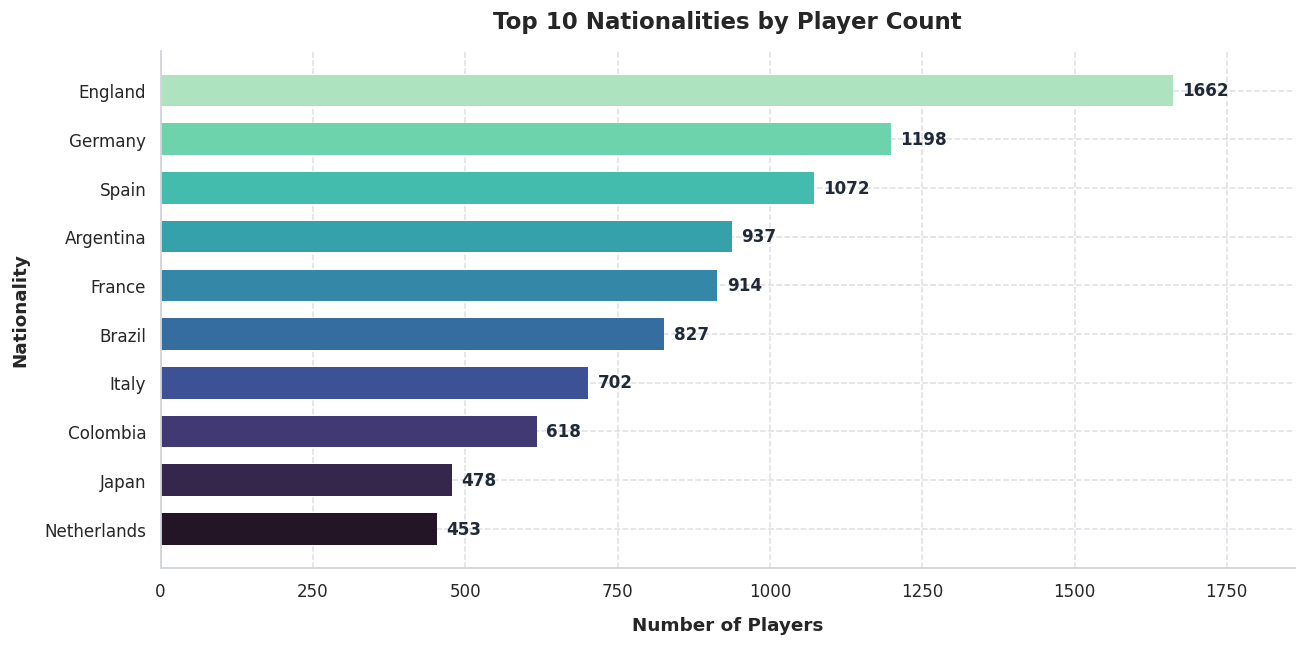

In [8]:
top_nations = df["Nationality"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("mako", len(top_nations))
bars = ax.barh(top_nations.index, top_nations.values, color=colors, edgecolor="none", height=0.65)

# Direct data value annotations
ax.bar_label(bars, fmt="%d", padding=6, fontweight="bold", color="#1F2937")

ax.set_title("Top 10 Nationalities by Player Count", fontsize=15, pad=15)
ax.set_xlabel("Number of Players", labelpad=10)
ax.set_ylabel("Nationality", labelpad=10)
ax.set_xlim(0, top_nations.max() * 1.12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** England, Germany, and Spain dominate the dataset player count, largely driven by the extensive multi-tier league systems (Premier League, EFL Championship, League One, League Two) represented in the game.

### 4.2 Squad Demographics: Player Distribution by Age Group

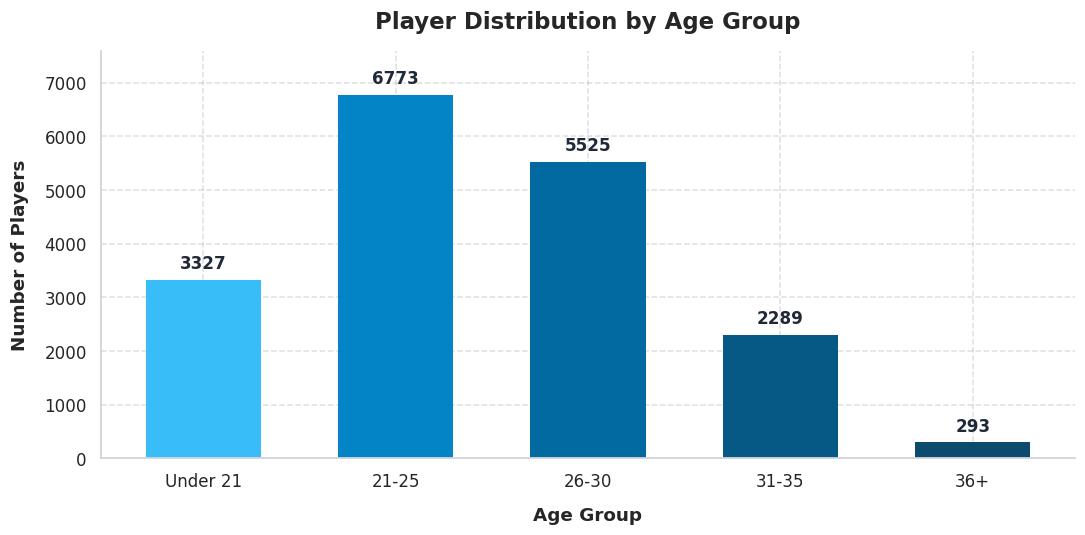

In [9]:
age_dist = df["Age Group"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#38BDF8", "#0284C7", "#0369A1", "#075985", "#0C4A6E"]
bars = ax.bar(age_dist.index.astype(str), age_dist.values, color=colors, width=0.6, edgecolor="none")

# Data labels on bars
ax.bar_label(bars, fmt="%d", padding=5, fontweight="bold", color="#1F2937")

ax.set_title("Player Distribution by Age Group", fontsize=15, pad=15)
ax.set_xlabel("Age Group", labelpad=10)
ax.set_ylabel("Number of Players", labelpad=10)
ax.set_ylim(0, age_dist.max() * 1.12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** The `21-25` cohort forms the largest segment of active professionals, followed closely by `26-30`. Together, players aged 21–30 make up more than 65% of the total roster pool, reflecting peak athletic prime.

### 4.3 Career Trajectory: Overall vs. Potential Ratings across Ages

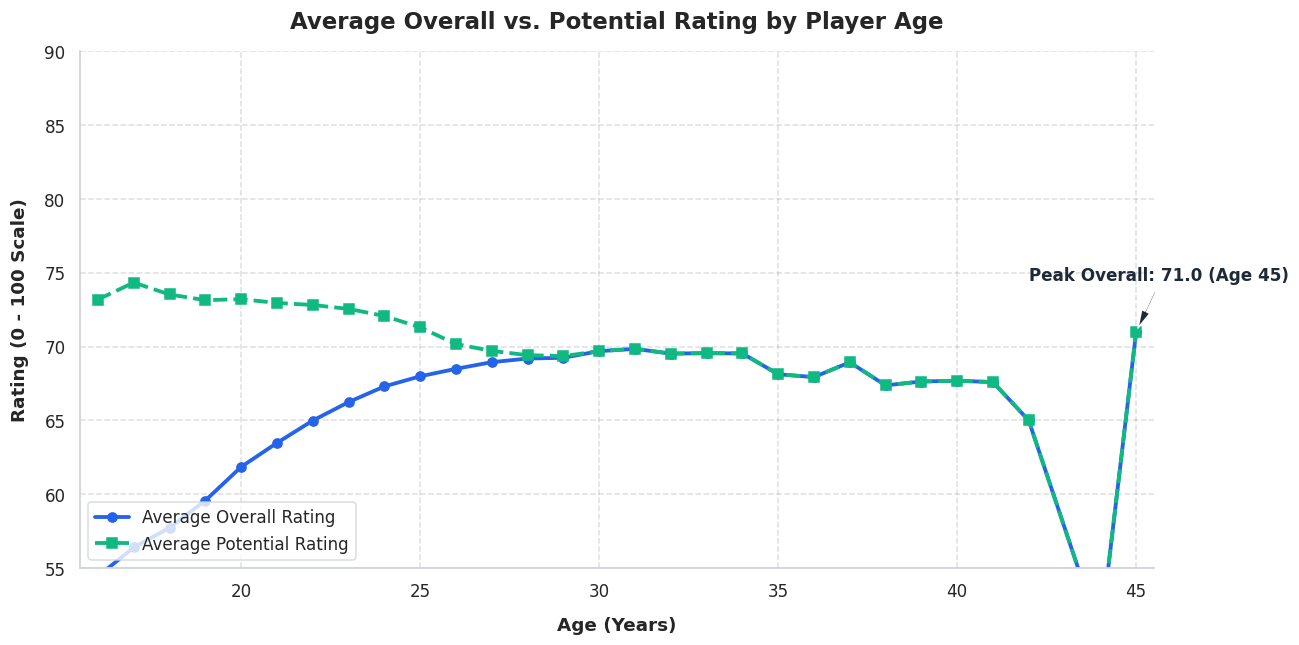

In [10]:
age_rating = df.groupby("Age", observed=True)[["Overall", "Potential"]].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(age_rating["Age"], age_rating["Overall"], marker="o", linewidth=2.5,
        color="#2563EB", label="Average Overall Rating")
ax.plot(age_rating["Age"], age_rating["Potential"], marker="s", linewidth=2.5,
        color="#10B981", linestyle="--", label="Average Potential Rating")

# Peak annotation
peak_overall_age = age_rating.loc[age_rating["Overall"].idxmax()]
ax.annotate(f"Peak Overall: {peak_overall_age['Overall']:.1f} (Age {int(peak_overall_age['Age'])})",
            xy=(peak_overall_age["Age"], peak_overall_age["Overall"]),
            xytext=(peak_overall_age["Age"] - 3, peak_overall_age["Overall"] + 3.5),
            arrowprops=dict(facecolor="#1F2937", shrink=0.08, width=1.2, headwidth=6),
            fontweight="bold", color="#1F2937")

ax.set_title("Average Overall vs. Potential Rating by Player Age", fontsize=15, pad=15)
ax.set_xlabel("Age (Years)", labelpad=10)
ax.set_ylabel("Rating (0 - 100 Scale)", labelpad=10)
ax.set_xlim(df["Age"].min() - 0.5, df["Age"].max() + 0.5)
ax.set_ylim(55, 90)
ax.legend(frameon=True, facecolor="white", edgecolor="#D1D5DB", loc="lower left", fontsize=11)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** The delta between `Potential` and `Overall` is widest in teenage years (under 20), narrowing rapidly until convergence around age 27–29. Peak overall capability plateaus between 28 and 32 years of age before veteran decline sets in.

### 4.4 Financial Valuation: Market Value vs. Overall Rating

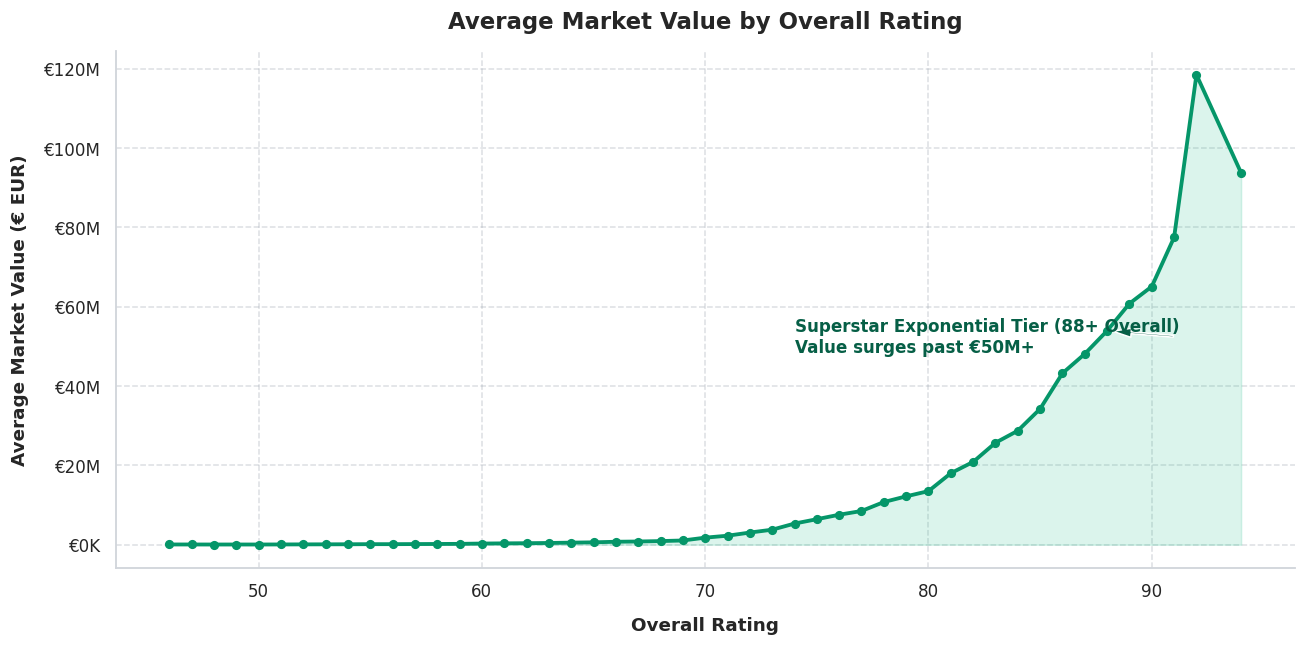

In [11]:
value_rating = df.groupby("Overall", observed=True)["Value"].mean().dropna().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(value_rating["Overall"], value_rating["Value"], marker="o", color="#059669",
        linewidth=2.5, markersize=5, label="Mean Market Value")
ax.fill_between(value_rating["Overall"], value_rating["Value"], color="#10B981", alpha=0.15)

# Format y-axis as Euros (€ Millions / Thousands)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"€{x/1e6:.0f}M" if x >= 1e6 else f"€{x/1e3:.0f}K"))

# Annotation for superstar tier
elite_tier = value_rating[value_rating["Overall"] >= 88].iloc[0]
ax.annotate(f"Superstar Exponential Tier (88+ Overall)\nValue surges past €50M+",
            xy=(elite_tier["Overall"], elite_tier["Value"]),
            xytext=(elite_tier["Overall"] - 14, elite_tier["Value"] * 0.9),
            arrowprops=dict(facecolor="#065F46", shrink=0.08, width=1.2, headwidth=6),
            fontweight="bold", color="#065F46")

ax.set_title("Average Market Value by Overall Rating", fontsize=15, pad=15)
ax.set_xlabel("Overall Rating", labelpad=10)
ax.set_ylabel("Average Market Value (€ EUR)", labelpad=10)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** Market value displays a steep exponential curve rather than a linear relationship. While players rated 70–80 trade at moderate valuations (€1M–€10M), ratings exceeding 85 command monumental premiums, exceeding €50M to €100M+ for world-class talent.

### 4.5 Elite Club Ranking: Average Overall Rating by Club

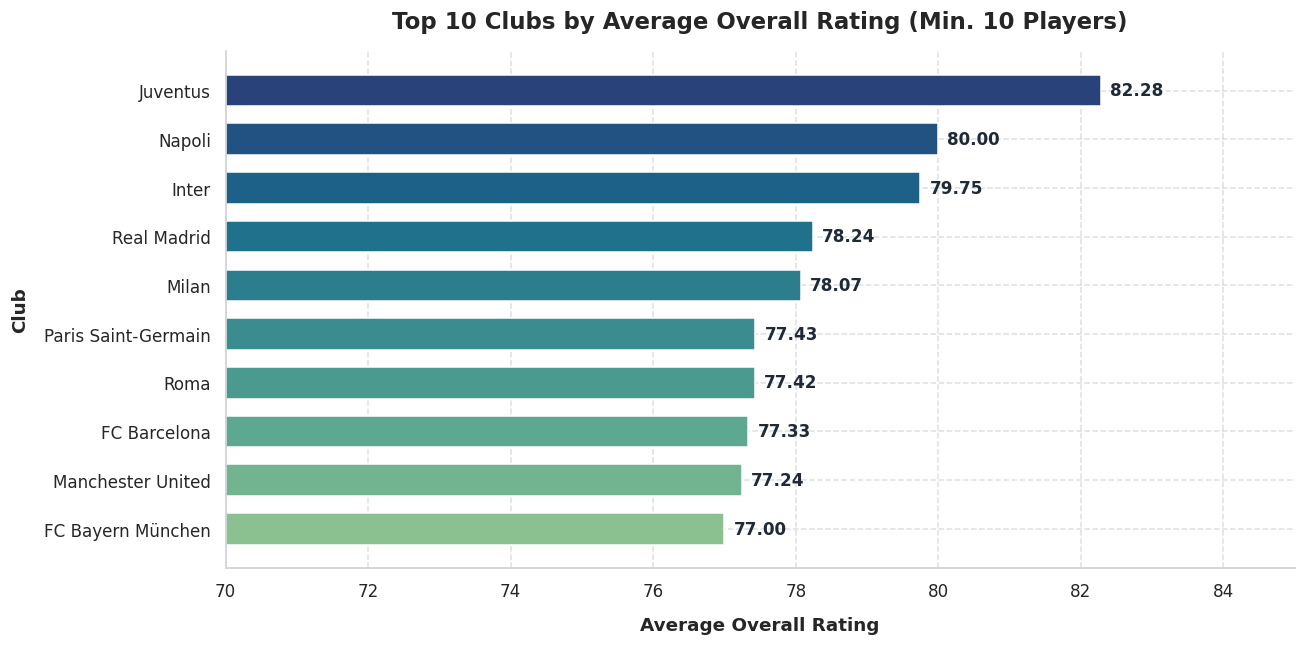

In [12]:
club_rating = df.dropna(subset=["Club"]).groupby("Club").agg(
    Average_Overall=("Overall", "mean"),
    Squad_Size=("ID", "count")
)
top_clubs = club_rating[club_rating["Squad_Size"] >= 10].nlargest(10, "Average_Overall").sort_values("Average_Overall")

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("crest", len(top_clubs))
bars = ax.barh(top_clubs.index, top_clubs["Average_Overall"], color=colors, height=0.65)

# Value labels on bars
ax.bar_label(bars, fmt="%.2f", padding=6, fontweight="bold", color="#1F2937")

ax.set_title("Top 10 Clubs by Average Overall Rating (Min. 10 Players)", fontsize=15, pad=15)
ax.set_xlabel("Average Overall Rating", labelpad=10)
ax.set_ylabel("Club", labelpad=10)
ax.set_xlim(70, 85)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** European powerhouses Juventus, Napoli, Barcelona, Real Madrid, and Bayern Munich lead global football with average squad ratings hovering between 77 and 82, demonstrating concentrated elite talent depth.

### 4.6 Positional Economics: Average Weekly Wage by Role

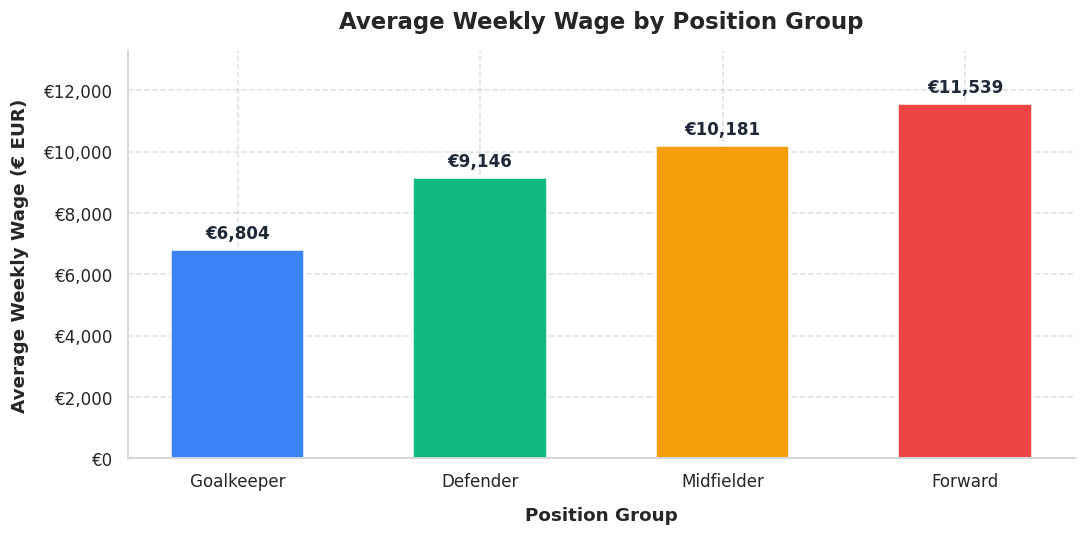

In [13]:
position_wage = df.groupby("Position Group", observed=True)["Wage"].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#3B82F6", "#10B981", "#F59E0B", "#EF4444"]
bars = ax.bar(position_wage.index, position_wage.values, color=colors, width=0.55)

# Value annotations formatted in Euros
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 250, f"€{yval:,.0f}",
            ha="center", va="bottom", fontweight="bold", color="#1F2937")

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"€{x:,.0f}"))
ax.set_title("Average Weekly Wage by Position Group", fontsize=15, pad=15)
ax.set_xlabel("Position Group", labelpad=10)
ax.set_ylabel("Average Weekly Wage (€ EUR)", labelpad=10)
ax.set_ylim(0, position_wage.max() * 1.15)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

> 💡 **Key Insight:** Forwards and Midfielders capture the highest average compensation packages in modern football, outpacing Defenders and Goalkeepers due to the market premium placed on match-winning offensive production and creative playmaking.

### 4.7 Wonderkids: Top 10 Under-21 Talents by Potential

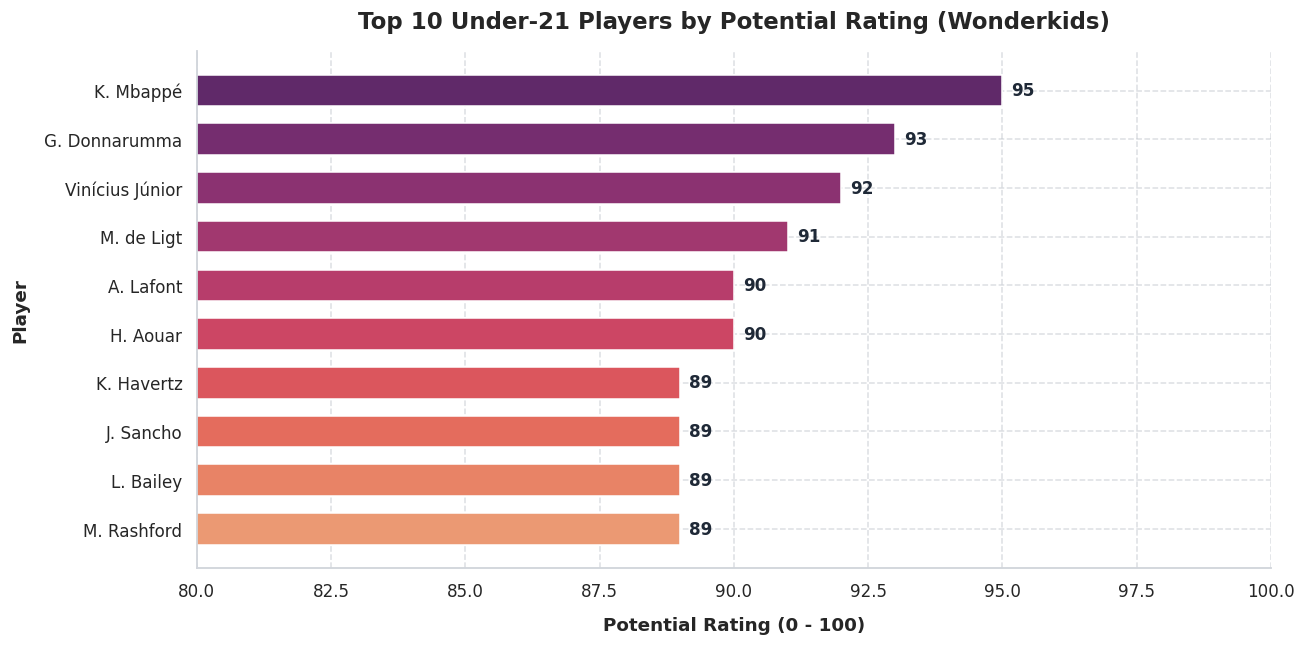

,Name,Age,Club,Nationality,Position,Overall,Potential,Potential Growth,Market Value
25,K. Mbappé,19.0,Paris Saint-Germain,France,RM,88.0,95,+7.0,€81.0M
229,G. Donnarumma,19.0,Milan,Italy,GK,82.0,93,+11.0,€29.0M
1143,Vinícius Júnior,17.0,Real Madrid,Brazil,LW,77.0,92,+15.0,€17.5M
226,M. de Ligt,18.0,Ajax,Netherlands,RCB,82.0,91,+9.0,€27.0M
415,H. Aouar,20.0,Olympique Lyonnais,France,LM,80.0,90,+10.0,€23.5M
734,A. Lafont,19.0,Fiorentina,France,GK,78.0,90,+12.0,€14.0M
321,L. Bailey,20.0,Bayer 04 Leverkusen,Jamaica,LM,81.0,89,+8.0,€26.5M
319,M. Rashford,20.0,Manchester United,England,LW,81.0,89,+8.0,€27.0M
1004,J. Sancho,18.0,Borussia Dortmund,England,RM,77.0,89,+12.0,€14.5M
413,K. Havertz,19.0,Bayer 04 Leverkusen,Germany,CAM,80.0,89,+9.0,€22.0M


In [14]:
under_21 = df[df["Age"] < 21].nlargest(10, "Potential")[
    ["Name", "Age", "Club", "Nationality", "Position", "Overall", "Potential", "Value"]
].sort_values("Potential")

fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette("flare", len(under_21))
bars = ax.barh(under_21["Name"], under_21["Potential"], color=colors, height=0.65)

# Value labels on bars
ax.bar_label(bars, fmt="%d", padding=6, fontweight="bold", color="#1F2937")

ax.set_title("Top 10 Under-21 Players by Potential Rating (Wonderkids)", fontsize=15, pad=15)
ax.set_xlabel("Potential Rating (0 - 100)", labelpad=10)
ax.set_ylabel("Player", labelpad=10)
ax.set_xlim(80, 100)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# Format and display the scouting table
wonderkids_table = under_21.sort_values("Potential", ascending=False).copy()
wonderkids_table["Potential Growth"] = "+" + (wonderkids_table["Potential"] - wonderkids_table["Overall"]).astype(str)
wonderkids_table["Market Value"] = wonderkids_table["Value"].apply(lambda x: f"€{x/1e6:.1f}M" if x >= 1e6 else f"€{x/1e3:.0f}K")
display(wonderkids_table[["Name", "Age", "Club", "Nationality", "Position", "Overall", "Potential", "Potential Growth", "Market Value"]])

> 💡 **Key Insight:** Kylian Mbappé leads all Under-21 players with an extraordinary 95 Potential rating, accompanied by established stars like Gianluigi Donnarumma, Gabriel Jesus, and Ousmane Dembélé who already boast high starting overall ratings and enormous room for growth.

## 5. Statistical Summaries & Comparative Insights

In [15]:
print("================================================================================")
print("📌 EXECUTIVE SUMMARY 1: TOP 10 PLAYER NATIONALITIES")
print("================================================================================")
top_nations_df = df["Nationality"].value_counts().head(10).rename_axis("Nationality").reset_index(name="Player Count")
top_nations_df["Share (%)"] = (top_nations_df["Player Count"] / len(df) * 100).round(2)
display(top_nations_df)

print("\n================================================================================")
print("📌 EXECUTIVE SUMMARY 2: RATING PROGRESSION BY AGE COHORT")
print("================================================================================")
age_summary = df.groupby("Age Group", observed=True).agg(
    Player_Count=("ID", "count"),
    Avg_Overall=("Overall", "mean"),
    Avg_Potential=("Potential", "mean"),
    Avg_Value_EUR=("Value", "mean"),
    Avg_Wage_EUR=("Wage", "mean")
).round(2)
display(age_summary)

print("\n================================================================================")
print("📌 EXECUTIVE SUMMARY 3: TOP 10 HIGHEST RATED CLUBS")
print("================================================================================")
display(top_clubs.sort_values("Average_Overall", ascending=False).round(2))

print("\n================================================================================")
print("📌 EXECUTIVE SUMMARY 4: POSITION GROUP ECONOMIC METRICS")
print("================================================================================")
pos_summary = df.groupby("Position Group", observed=True).agg(
    Player_Count=("ID", "count"),
    Avg_Overall=("Overall", "mean"),
    Avg_Wage_EUR=("Wage", "mean"),
    Avg_Value_EUR=("Value", "mean")
).round(2)
display(pos_summary)

print("\n================================================================================")
print("📌 EXECUTIVE SUMMARY 5: CORE NUMERICAL ATTRIBUTES DISTRIBUTION")
print("================================================================================")
display(df[["Age", "Overall", "Potential", "Value", "Wage", "Release Clause"]].describe().round(2))

📌 EXECUTIVE SUMMARY 1: TOP 10 PLAYER NATIONALITIES


,Nationality,Player Count,Share (%)
0,England,1662,9.13
1,Germany,1198,6.58
2,Spain,1072,5.89
3,Argentina,937,5.15
4,France,914,5.02
5,Brazil,827,4.54
6,Italy,702,3.86
7,Colombia,618,3.39
8,Japan,478,2.63
9,Netherlands,453,2.49



📌 EXECUTIVE SUMMARY 2: RATING PROGRESSION BY AGE COHORT


,Player_Count,Avg_Overall,Avg_Potential,Avg_Value_EUR,Avg_Wage_EUR
Age Group,,,,,
Under 21,3327,59.69,73.36,894567.18,3312.29
21-25,6773,65.97,72.35,2580681.38,8787.39
26-30,5525,69.06,69.71,3255666.97,13474.57
31-35,2289,69.52,69.52,2316535.61,13296.20
36+,293,67.99,67.99,499146.76,6003.41



📌 EXECUTIVE SUMMARY 3: TOP 10 HIGHEST RATED CLUBS


,Average_Overall,Squad_Size
Club,,
Juventus,82.28,25
Napoli,80.00,25
Inter,79.75,24
Real Madrid,78.24,33
Milan,78.07,27
Paris Saint-Germain,77.43,30
Roma,77.42,26
FC Barcelona,77.33,33
Manchester United,77.24,33



📌 EXECUTIVE SUMMARY 4: POSITION GROUP ECONOMIC METRICS


,Player_Count,Avg_Overall,Avg_Wage_EUR,Avg_Value_EUR
Position Group,,,,
Defender,5866,66.40,9146.10,1975138.08
Forward,3478,66.31,11539.39,2937566.13
Goalkeeper,2025,64.59,6803.95,1585814.81
Midfielder,6838,66.55,10180.61,2760639.08



📌 EXECUTIVE SUMMARY 5: CORE NUMERICAL ATTRIBUTES DISTRIBUTION


,Age,Overall,Potential,Value,Wage,Release Clause
count,18207.00,18207.00,18207.00,1.820700e+04,18207.00,1.820700e+04
mean,25.12,66.24,71.31,2.410696e+06,9731.31,4.285691e+06
std,4.67,6.91,6.14,5.594933e+06,21999.29,1.067518e+07
min,16.00,46.00,48.00,0.000000e+00,0.00,1.300000e+04
25%,21.00,62.00,67.00,3.000000e+05,1000.00,5.700000e+05
50%,25.00,66.00,71.00,6.750000e+05,3000.00,1.100000e+06
75%,28.00,71.00,75.00,2.000000e+06,9000.00,3.000000e+06
max,45.00,94.00,95.00,1.185000e+08,565000.00,2.281000e+08


## 6. Clean Dataset Export

In [16]:
output_filename = "fifa19_cleaned.csv"
df.to_csv(output_filename, index=False)
file_size_mb = os.path.getsize(output_filename) / (1024 * 1024)

print(f"✓ Cleaned dataset successfully exported to '{output_filename}' ({file_size_mb:.2f} MB)")
print(f"✓ Total records exported: {len(df):,} rows with {df.shape[1]} columns.")

✓ Cleaned dataset successfully exported to 'fifa19_cleaned.csv' (10.69 MB)
✓ Total records exported: 18,207 rows with 90 columns.
